## Дерева рішень, Random Forest і XGBoost у багатокласовій класифікації з пропущеними значеннями (датасет Annealing)

**Мета:** порівняти Decision Tree, Random Forest і XGBoost на датасеті з великою кількістю пропусків; дослідити вплив індикаторів пропусків, коректно (без витоку) підібрати гіперпараметри Optuna, чесно оцінити моделі вкладеною CV, статистично порівняти їх і проінтерпретувати (MDI, permutation importance, SHAP).

Варіант: **N = 10 → SEED = 52**. Датасет — версія OpenML (898 спостережень).

In [22]:
import os, time, warnings, itertools
import importlib.metadata as importlib_md
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from IPython.display import display

N = 10
SEED = 42 + N
N_TRIALS = 30                  
OUTER_SPLITS, INNER_SPLITS = 5, 3
RECOMPUTE = False               
np.random.seed(SEED)

import sklearn, scipy, xgboost, optuna, shap

def silence_warnings():
    """Прибирає відомі й нешкідливі попередження (викликається і в паралельних процесах)."""
    warnings.filterwarnings("ignore", message="Skipping features without any observed values")
    warnings.filterwarnings("ignore", message=".*is experimental.*")
    warnings.filterwarnings("ignore", category=FutureWarning)
    warnings.filterwarnings("ignore", category=matplotlib.MatplotlibDeprecationWarning)
    warnings.filterwarnings("ignore", message=".*IProgress.*")
    optuna.logging.set_verbosity(optuna.logging.WARNING)
silence_warnings()

MODELS = ["DT", "RF", "XGB"]
MODEL_NAMES = {"DT": "Decision Tree", "RF": "Random Forest", "XGB": "XGBoost"}
COLOR = {"DT": "#f28e2b", "RF": "#4e79a7", "XGB": "#59a14f"}
C_A, C_B, C_BAD, C_IND = "#9aa5b1", "#1b998b", "#d1495b", "#e08e0b"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 50, "display.width", 180)

def pm(a):
    """Формат «середнє ± стандартне відхилення»."""
    return f"{np.mean(a):.4f} ± {np.std(a, ddof=1):.4f}"

print(f"N = {N} -> SEED = {SEED}")
for p in ["scikit-learn", "xgboost", "optuna", "shap", "pandas", "numpy", "scipy", "matplotlib", "seaborn"]:
    print(f"{p:<13}", importlib_md.version(p))

N = 10 -> SEED = 52
scikit-learn  1.9.1
xgboost       3.4.1
optuna        5.0.0
shap          0.53.0
pandas        3.0.6
numpy         2.5.3
scipy         1.18.1
matplotlib    3.11.2
seaborn       0.13.2


## 1. Первинний аналіз даних
### 1.1 Завантаження, типи ознак

In [23]:
from sklearn.datasets import fetch_openml
from urllib.parse import unquote

data = fetch_openml(name="anneal", version=1, as_frame=True)
X, y = data.data.copy(), data.target.copy()
X.columns = [unquote(c).replace("/", "_") for c in X.columns]
for c in X.columns:                                  
    if not pd.api.types.is_numeric_dtype(X[c]):
        s = X[c].astype(object)
        X[c] = s.where(s.notna(), np.nan)
X, y = X.reset_index(drop=True), y.astype(str).reset_index(drop=True)

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print(f"Спостережень: {X.shape[0]}, ознак: {X.shape[1]} (числових: {len(num_cols)}, категоріальних: {len(cat_cols)})")
print("Числові:", num_cols)

Спостережень: 898, ознак: 38 (числових: 6, категоріальних: 32)
Числові: ['carbon', 'hardness', 'strength', 'thick', 'width', 'len']


Датасет із OpenML має **898 спостережень і 38 ознак** (я використовую саме цю версію, а не 798-рядкову з UCI). Числових ознак лише 6 (`carbon`, `hardness`, `strength`, `thick`, `width`, `len`), решта 32 категоріальні: коди сталі, типи обробки, форма тощо. Категоріальні ознаки я перевожу в тип `object`, а всі пропуски — в єдиний `NaN`, щоб `SimpleImputer` і `make_column_selector` правильно їх розпізнавали.

### 1.2 Частка пропусків; видалення порожніх і константних ознак

Повністю порожні: ['m', 'marvi', 'corr', 'jurofm', 's', 'p']
Константні (одне значення, без пропусків): ['product-type']


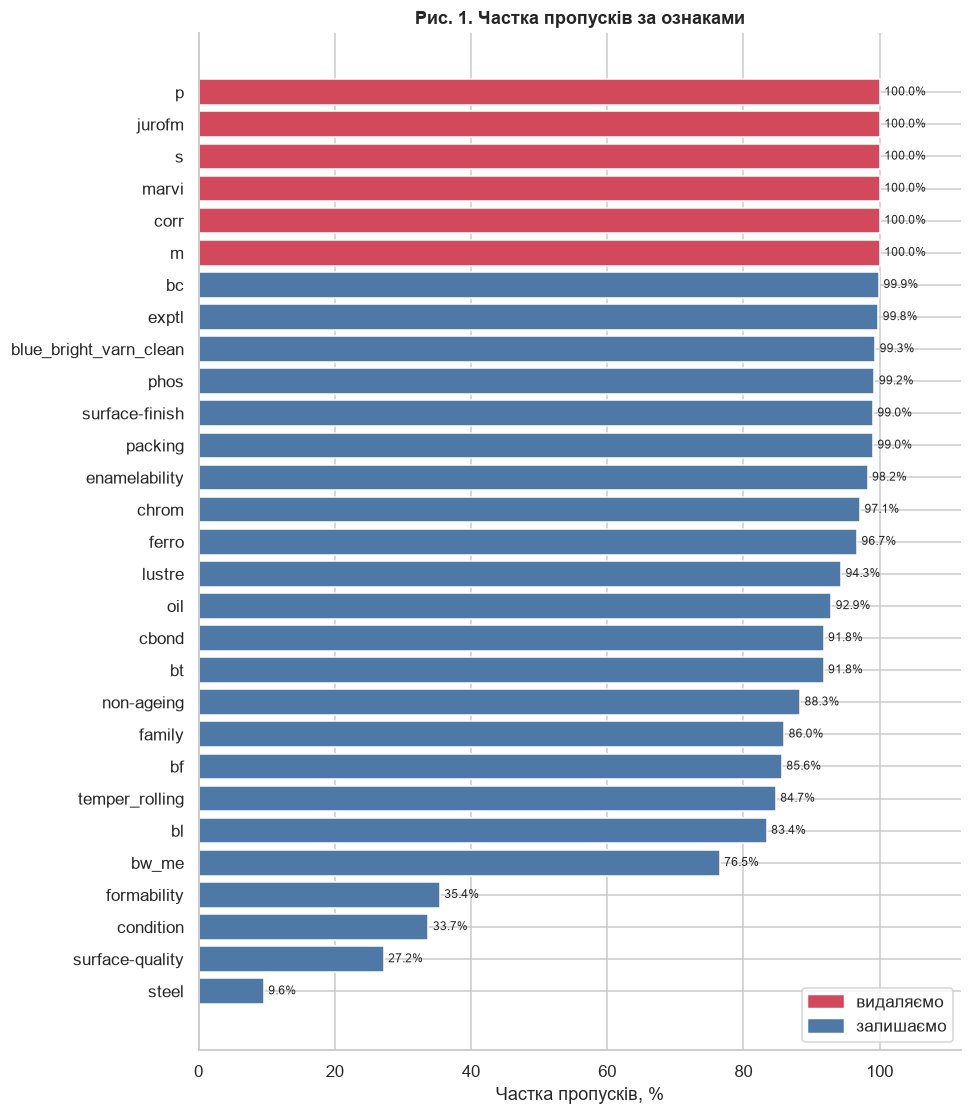

Залишилось ознак: 31
Ознак без пропусків: 8, з часткою пропусків > 90 %: 13


In [24]:
miss = X.isna().mean()
empty_cols = [c for c in X.columns if X[c].isna().all()]
constant_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1 and c not in empty_cols]
drop_cols = empty_cols + constant_cols
print("Повністю порожні:", empty_cols)
print("Константні (одне значення, без пропусків):", constant_cols)

m = miss[miss > 0].sort_values()
fig, ax = plt.subplots(figsize=(9, 0.3 * len(m) + 1.6))
bars = ax.barh(m.index, m.values * 100, color=[C_BAD if c in drop_cols else "#4e79a7" for c in m.index])
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
ax.set_xlim(0, 112); ax.set_xlabel("Частка пропусків, %")
ax.set_title("Рис. 1. Частка пропусків за ознаками")
ax.legend(handles=[Patch(color=C_BAD, label="видаляємо"), Patch(color="#4e79a7", label="залишаємо")], loc="lower right")
plt.tight_layout(); plt.show()

X = X.drop(columns=drop_cols)
print(f"Залишилось ознак: {X.shape[1]}")
print(f"Ознак без пропусків: {(X.isna().mean() == 0).sum()}, з часткою пропусків > 90 %: {(X.isna().mean() > 0.9).sum()}")

Спочатку я дивлюсь, скільки в ознаках пропусків, і бачу дуже незвичну картину. Пропусків або майже немає, або їх 90–99,9 %, а середніх варіантів майже не трапляється. Повністю порожніх ознак шість (`m`, `marvi`, `corr`, `jurofm`, `s`, `p`). Ще `product-type` в усіх 898 рядках має одне й те саме значення. Ці 7 ознак я видаляю, бо вони нічого не можуть сказати про клас: якщо значення всюди однакове або його взагалі немає, модель не має за що «зачепитися». Лишається 31 ознака.

Ознаки, де є одне значення **і** пропуски (наприклад, `bc`, `exptl`), я навмисно залишаю. Для них важливе не саме значення, а те, **є воно чи ні**. У документації `anneal.names` сказано, що багато пропусків тут **структурні**: якась характеристика просто не стосується певного виробу.

### 1.3 Розподіл цільової змінної

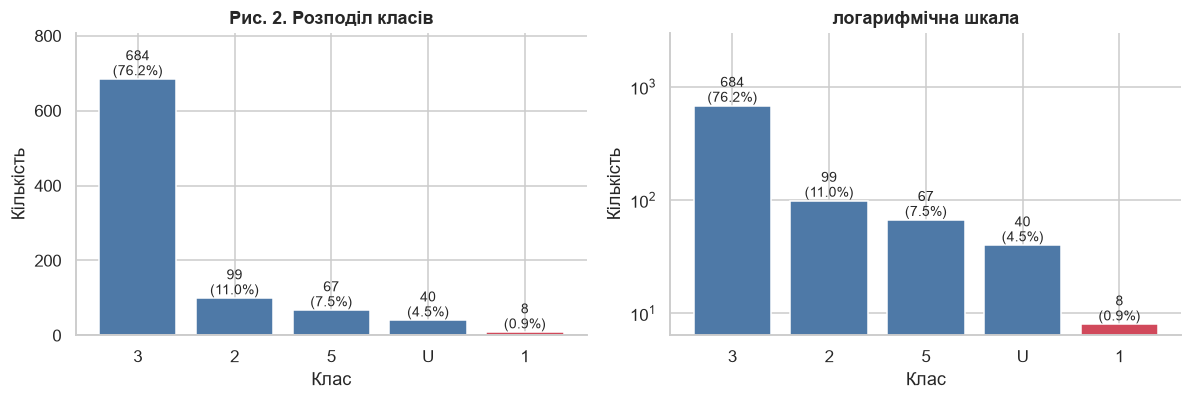

class
3    684
2     99
5     67
U     40
1      8


In [25]:
counts = y.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, log in zip(axes, [False, True]):
    bars = ax.bar(counts.index, counts.values, color=["#4e79a7"] * (len(counts) - 1) + [C_BAD])
    ax.bar_label(bars, labels=[f"{v}\n({v / len(y):.1%})" for v in counts.values], fontsize=9)
    ax.set_xlabel("Клас"); ax.set_ylabel("Кількість")
    if log: ax.set_yscale("log"); ax.set_ylim(top=3000)
    else: ax.set_ylim(top=counts.max() * 1.18)
axes[0].set_title("Рис. 2. Розподіл класів"); axes[1].set_title("логарифмічна шкала")
plt.tight_layout(); plt.show()
print(counts.to_string())

Класи дуже нерівні. Клас `3` — це 684 об'єкти, тобто 76 % усіх даних, а клас `1` має лише 8 об'єктів (менше 1 %). Клас `4` є в документації, але в даних його немає взагалі. Через це accuracy тут мало що означає: модель, яка завжди відповідає «3», уже отримала б 76 %. Тому головною метрикою я беру **macro F1**, де кожен клас важить однаково.

Клас `1` я **залишаю**. Якщо об'єднати його з іншим класом, задача стане вже іншою, а якщо викинути, модель ніколи не навчиться його розпізнавати. У train потрапить 6 об'єктів цього класу, і для 5-блочної CV цього вистачає (у п. 4.2 я ще раз перевіряю, що в кожному навчальному блоці є мінімум 4 об'єкти). Мінус у тому, що в кожному валідаційному блоці буде лише 1–2 об'єкти класу `1`. Одна помилка на такому об'єкті сильно «просаджує» macro F1, тому результати CV будуть стрибати від блоку до блоку, і я очікується великий розкид.

### 1.4 Аналіз механізму пропусків
Для 5 ознак із найбільшою (але не 100 %) часткою пропусків будуємо таблиці «пропуск / є значення» × клас і перевіряємо незалежність. У таблицях багато клітинок з очікуваною частотою < 5, тому крім χ² рахуємо **Monte-Carlo p-значення**: 5000 перестановок міток класу. Це аналог точного тесту Фішера для таблиць 2×K. Поріг значущості з поправкою Бонфероні: 0.05 / 5 = 0.01.

In [26]:
from scipy.stats import chi2_contingency

codes, _ = pd.factorize(y, sort=True)
K_all = codes.max() + 1

def chi2_stat(table):
    table = table[:, table.sum(axis=0) > 0]
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / table.sum()
    return ((table - expected) ** 2 / expected).sum()

def monte_carlo_p(flag, n_perm=5000):
    rng = np.random.default_rng(SEED)
    table = lambda c: np.bincount(flag * K_all + c, minlength=2 * K_all).reshape(2, K_all)
    obs = chi2_stat(table(codes))
    perm = np.array([chi2_stat(table(rng.permutation(codes))) for _ in range(n_perm)])
    return (1 + np.sum(perm >= obs - 1e-12)) / (1 + n_perm)

m = X.isna().mean()
top5 = m[(m > 0) & (m < 1)].sort_values(ascending=False).head(5).index
tables, rows = {}, []
for f in top5:
    flag = X[f].isna().astype(int).values
    ct = pd.crosstab(np.where(flag == 1, "пропуск", "є значення"), y.values)
    ct.index.name, ct.columns.name = f, "клас"
    tables[f] = ct
    _, p_chi, _, E = chi2_contingency(ct.values)
    rows.append({"ознака": f, "% пропусків": round(flag.mean() * 100, 1), "p (χ²)": p_chi,
                 "клітинок з E<5": f"{(E < 5).mean():.0%}", "p (Monte-Carlo)": monte_carlo_p(flag)})
display(pd.concat(tables, names=["ознака"]))
mech = pd.DataFrame(rows).set_index("ознака")
mech["залежить від класу?"] = np.where(mech["p (Monte-Carlo)"] < 0.05 / len(mech), "так", "ні")
display(mech.round(4))
n_dep = int((mech["залежить від класу?"] == "так").sum())

клас                               1   2    3   5   U
ознака                 bc                            
bc                     пропуск     8  99  683  67  40
                       є значення  0   0    1   0   0
exptl                  пропуск     6  99  684  67  40
                       є значення  2   0    0   0   0
blue_bright_varn_clean пропуск     7  95  683  67  40
                       є значення  1   4    1   0   0
phos                   пропуск     8  99  684  60  40
                       є значення  0   0    0   7   0
surface-finish         пропуск     8  90  684  67  40
                       є значення  0   9    0   0   0

,% пропусків,p (χ²),клітинок з E<5,p (Monte-Carlo),залежить від класу?
ознака,,,,,
bc,99.9,0.9889,50%,1.0000,ні
exptl,99.8,0.0000,50%,0.0002,так
blue_bright_varn_clean,99.3,0.0000,50%,0.0008,так
phos,99.2,0.0000,40%,0.0002,так
surface-finish,99.0,0.0000,40%,0.0002,так


Тут я перевіряю, чи пропуски випадкові (MCAR), чи пов'язані з класом. У таблицях добре видно, що пропуски зовсім не випадкові:
* `phos` заповнена лише у 7 об'єктах, і **всі вони з класу `5`**;
* `exptl` заповнена у 2 об'єктах, і обидва з **класу `1`**;
* `surface-finish` заповнена у 9 об'єктах, і всі вони з **класу `2`**.

Тести це підтверджують: для 4 з 5 ознак p-значення 0.0002–0.0008, тобто набагато менше за поріг 0.01 (поріг я зменшую поправкою Бонфероні, бо роблю 5 тестів одразу). Класичний χ² теж дає p ≈ 0, але йому тут не дуже можна вірити, бо в 40–50 % клітинок очікувана частота менша за 5. Тому я більше покладаюсь на перестановочний (Monte-Carlo) тест. Для `bc` залежності не видно, але там лише одне непорожнє значення на весь датасет, тож тест просто нічого не може показати.

**Висновок:** пропуски тут **не MCAR**, бо сам факт пропуску підказує клас. MAR це чи MNAR, за даними сказати неможливо. Я формулюю гіпотезу, що прапорці пропусків (варіант B) мають помітно допомогти моделям.

### 1.5 Кодування цільової змінної

In [27]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder().fit(y)
y_enc = le.transform(y)
CLASS_NAMES = [str(c) for c in le.classes_]
K = len(CLASS_NAMES)
print("Класи ->", dict(zip(CLASS_NAMES, range(K))))

Класи -> {'1': 0, '2': 1, '3': 2, '5': 3, 'U': 4}


XGBoost вимагає, щоб класи були числами від 0 до K−1, тому я кодую їх через `LabelEncoder`: `1→0`, `2→1`, `3→2`, `5→3`, `U→4`. Клас `4` у даних відсутній, тому в кодуванні його теж немає, і всього виходить K = 5 класів. На графіках і в таблицях я показую оригінальні назви класів, щоб не плутатись.

## 2. Поділ даних і пайплайни обробки

In [28]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED)
display(pd.DataFrame({"усього": np.bincount(y_enc), "train": np.bincount(y_train), "test": np.bincount(y_test)}, index=CLASS_NAMES).T)

,1,2,3,5,U
усього,8,99,684,67,40
train,6,79,547,54,32
test,2,20,137,13,8


Ділю дані 80/20 зі стратифікацією, тому частки класів у train і test однакові. Але в тест потрапило лише **2 об'єкти класу `1`** і 8 об'єктів класу `U`, тож тестові метрики для рідких класів будуть дуже «хиткими»: одна помилка змінить результат на десятки відсотків. Тест я відкладаю й чіпаю тільки один раз, у розділі 6.

Уся обробка (заповнення пропусків, one-hot, прапорці) захована всередину `Pipeline`. Це важливо, бо в кожному блоці CV імпутер «вчиться» лише на тренувальній частині й не бачить валідаційну, тож витоку даних немає. Імпутацію я роблю навмисно, хоча всі три моделі вміють працювати з NaN самі: так усі моделі отримують однакові дані, і порівняння чесне.

In [29]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def build_preprocessor(with_indicators):
    parts = [("num", SimpleImputer(strategy="median"), make_column_selector(dtype_include="number")),
             ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                               ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
              make_column_selector(dtype_exclude="number"))]
    if with_indicators:
        parts.append(("miss", MissingIndicator(features="missing-only"), make_column_selector()))
    return ColumnTransformer(parts)

def make_model(name, params=None, n_jobs=-1):
    params = params or {}
    if name == "DT":
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == "RF":
        return RandomForestClassifier(random_state=SEED, n_jobs=n_jobs, **params)
    return XGBClassifier(random_state=SEED, n_jobs=n_jobs, eval_metric="mlogloss", **params)

def build_pipeline(name, with_indicators=True, params=None, n_jobs=-1):
    return Pipeline([("prep", build_preprocessor(with_indicators)), ("clf", make_model(name, params, n_jobs))])

Функції `build_preprocessor`, `make_model` і `build_pipeline` повторюють шаблон із завдання. Я додаю лише параметр `n_jobs`, щоб при паралельному запуску вкладеної CV кожна модель працювала в одному потоці й процеси не «билися» за ядра процесора. У варіанті B `MissingIndicator(features='missing-only')` додає прапорці лише для тих ознак, у яких у train справді були пропуски. У моєму випадку вийшло 23 прапорці.

## 3. Базові моделі (типові параметри)
Повторна стратифікована CV 5×3 (15 оцінок) на train. Для **всіх** моделей і обох варіантів використовується один об'єкт `cv`, тож блоки однакові, і можливе парне порівняння в розділі 5.

In [30]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

scoring = {"acc": "accuracy", "f1m": "f1_macro", "bacc": "balanced_accuracy"}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
cv_res = {(v, m): cross_validate(build_pipeline(m, flag), X_train, y_train, cv=cv, scoring=scoring)
          for v, flag in [("A", False), ("B", True)] for m in MODELS}

def cv_table(v):
    return pd.DataFrame({MODEL_NAMES[m]: {"Accuracy": pm(cv_res[(v, m)]["test_acc"]),
                                          "Macro F1": pm(cv_res[(v, m)]["test_f1m"]),
                                          "Balanced acc.": pm(cv_res[(v, m)]["test_bacc"]),
                                          "fit, с": f"{cv_res[(v, m)]['fit_time'].mean():.2f}"} for m in MODELS}).T
print("Таблиця 1. CV 5×3, варіант A, типові параметри"); display(cv_table("A"))
print("Таблиця 2. CV 5×3, варіант B, типові параметри"); display(cv_table("B"))

Таблиця 1. CV 5×3, варіант A, типові параметри


,Accuracy,Macro F1,Balanced acc.,"fit, с"
Decision Tree,0.9499 ± 0.0212,0.8657 ± 0.1000,0.8693 ± 0.0975,0.01
Random Forest,0.9587 ± 0.0146,0.9008 ± 0.0859,0.8944 ± 0.0941,0.11
XGBoost,0.9568 ± 0.0188,0.8698 ± 0.1112,0.8683 ± 0.1126,0.17


Таблиця 2. CV 5×3, варіант B, типові параметри


,Accuracy,Macro F1,Balanced acc.,"fit, с"
Decision Tree,0.9902 ± 0.0095,0.9507 ± 0.0692,0.9468 ± 0.0694,0.01
Random Forest,0.9930 ± 0.0083,0.9538 ± 0.0775,0.9444 ± 0.0860,0.11
XGBoost,0.9884 ± 0.0090,0.9118 ± 0.0941,0.9109 ± 0.0973,0.14


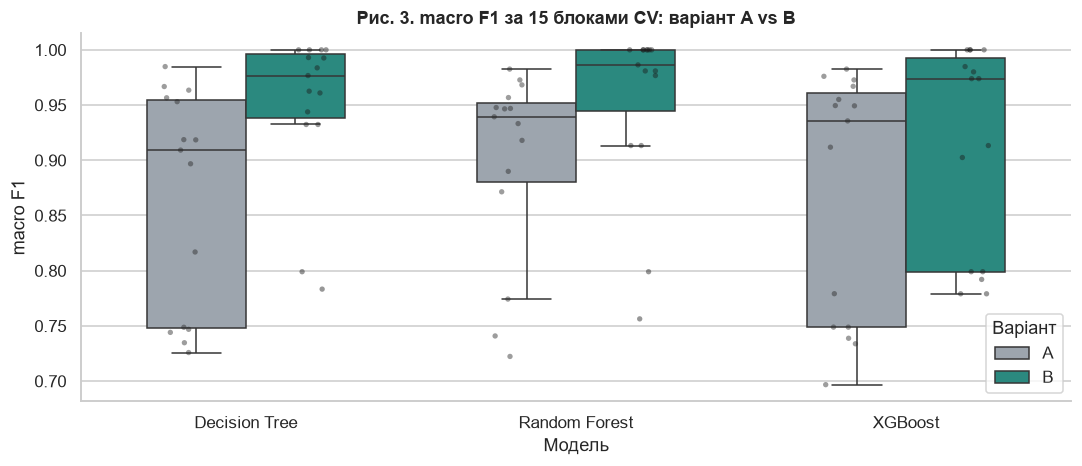

In [31]:
df_cv = pd.DataFrame([{"Модель": MODEL_NAMES[m], "Варіант": v, "macro F1": s}
                      for (v, m), r in cv_res.items() for s in r["test_f1m"]])
fig, ax = plt.subplots(figsize=(10, 4.4))
sns.boxplot(data=df_cv, x="Модель", y="macro F1", hue="Варіант", palette=[C_A, C_B], showfliers=False, width=0.6, ax=ax)
sns.stripplot(data=df_cv, x="Модель", y="macro F1", hue="Варіант", dodge=True, color="k", alpha=0.45, size=3.5, legend=False, ax=ax)
ax.set_title("Рис. 3. macro F1 за 15 блоками CV: варіант A vs B"); ax.legend(title="Варіант", loc="lower right")
plt.tight_layout(); plt.show()

**Аналіз.**
* Якщо дивитись лише на accuracy, усі моделі виглядають майже однаково (0.95–0.99). Це той самий «ефект стелі», про який сказано в завданні. Різницю видно лише в macro F1 і balanced accuracy.
* **Прапорці пропусків допомогли всім трьом моделям.** Macro F1 зріс у Decision Tree з 0.866 до 0.951 (+0.085), у Random Forest з 0.901 до 0.954 (+0.053), у XGBoost з 0.870 до 0.912 (+0.042). Accuracy піднялась з ~0.95 до ~0.99. Тобто моя гіпотеза з п. 1.4 справдилась: коли модель знає, що «значення не було», їй легше вгадати клас. Найбільше виграло одне дерево. Мабуть, тому, що без прапорців йому найважче «здогадатися» про пропуск по заповненому значенню.
* Розкид дуже великий (± 0.07–0.11), і на графіку видно окремі блоки, де macro F1 падає до 0.7–0.8. Це якраз блоки, де помилились на 1–2 об'єктах класу `1`. Тому за самими середніми робити висновки не можна, потрібен статистичний тест (розділ 5).
* У варіанті B найкращий за середнім **Random Forest (0.954)**, дерево майже поруч (0.951), а XGBoost зі стандартними параметрами відстає (0.912).

## 4. Підбір гіперпараметрів (Optuna, варіант B)
У цільову функцію передається **весь пайплайн** (обробка + модель), тож імпутер навчається лише на тренувальних частинах внутрішньої CV. Тестова вибірка тут не використовується.

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

def suggest_params(trial, name):
    if name == "DT":
        return {"max_depth": trial.suggest_int("max_depth", 2, 20),
                "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
                "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])}
    if name == "RF":
        return {"n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
                "max_depth": trial.suggest_int("max_depth", 3, 30),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
                "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5]),
                "class_weight": trial.suggest_categorical("class_weight", [None, "balanced", "balanced_subsample"])}
    return {"n_estimators": trial.suggest_int("n_estimators", 50, 400),
            "max_depth": trial.suggest_int("max_depth", 2, 10),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "min_child_weight": trial.suggest_float("min_child_weight", 1, 10, log=True)}

def tune(name, X_tr, y_tr, n_trials=N_TRIALS, n_jobs=-1):
    inner = StratifiedKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED)
    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name), n_jobs=n_jobs)
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring="f1_macro").mean()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

### 4.2 Вкладена крос-валідація
Зовнішня 5-блочна CV оцінює якість. На кожному зовнішньому блоці `tune()` запускається **лише на його тренувальній частині**, а якість рахується на валідаційній. На тих самих блоках для порівняння оцінюється й модель із типовими параметрами.

Це найдовший етап: 3 моделі × 5 блоків × 30 спроб × 3 внутрішні блоки ≈ 1350 навчань. Щоб прискорити, 15 незалежних задач (модель × блок) виконуються **паралельно** (`joblib`), а результати кешуються в `models/nested_cv.joblib`. Повторний запуск ноутбука бере кеш, а для повного перерахунку треба поставити `RECOMPUTE = True`. Сід кожної задачі фіксований, тому результат не залежить від того, послідовно чи паралельно її виконано.

In [33]:
import joblib
from joblib import Parallel, delayed
from sklearn.metrics import f1_score

os.makedirs("models", exist_ok=True)
outer = StratifiedKFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=SEED)
folds = list(outer.split(X_train, y_train))
print("Мінімум об'єктів класу в навчальній частині зовнішніх блоків:",
      [int(np.bincount(y_train[tr], minlength=K).min()) for tr, _ in folds])

def nested_job(name, tr, va):
    silence_warnings()                                       # у дочірньому процесі фільтри треба ввімкнути заново
    X_tr, y_tr, X_va, y_va = X_train.iloc[tr], y_train[tr], X_train.iloc[va], y_train[va]
    study = tune(name, X_tr, y_tr, n_jobs=1)
    tuned = build_pipeline(name, True, study.best_params, n_jobs=1).fit(X_tr, y_tr)
    default = build_pipeline(name, True, n_jobs=1).fit(X_tr, y_tr)
    return name, f1_score(y_va, tuned.predict(X_va), average="macro"), \
           f1_score(y_va, default.predict(X_va), average="macro"), study.best_value

cache = "models/nested_cv.joblib"
if os.path.exists(cache) and not RECOMPUTE:
    nested = joblib.load(cache); print("Взято з кешу:", cache)
else:
    t0 = time.time()
    out = Parallel(n_jobs=-1)(delayed(nested_job)(m, tr, va) for m in MODELS for tr, va in folds)
    nested = {m: {"tuned": [], "default": [], "inner_best": []} for m in MODELS}
    for m, t, d, b in out:
        nested[m]["tuned"].append(t); nested[m]["default"].append(d); nested[m]["inner_best"].append(b)
    joblib.dump(nested, cache); print(f"Пораховано за {(time.time() - t0) / 60:.1f} хв")
for m in MODELS:
    print(f"{MODEL_NAMES[m]:<14} по блоках: {np.round(nested[m]['tuned'], 4)}")

Мінімум об'єктів класу в навчальній частині зовнішніх блоків: [5, 5, 4, 5, 5]
Взято з кешу: models/nested_cv.joblib
Decision Tree  по блоках: [1.     1.     0.7982 0.7825 0.9926]
Random Forest  по блоках: [0.9837 1.     0.9064 0.9701 1.    ]
XGBoost        по блоках: [0.9638 1.     0.7791 0.9848 0.9809]


Перевірка «типової помилки №4» проходить: у кожному навчальному блоці зовнішньої CV є щонайменше 4 об'єкти найменшого класу, тож внутрішня 3-блочна CV працює без помилок. Результати по блоках дуже нерівні. В одних блоках моделі мають ідеальне 1.000, а в 3-му блоці DT і XGBoost падають до ~0.78–0.80. Саме в цей блок потрапили «важкі» об'єкти рідкісних класів. Це ще раз показує, що одне число без розкиду тут мало що каже.

### 4.3 Фінальні моделі: оптимізація на всьому train

In [34]:
def final_job(name):
    silence_warnings()
    study = tune(name, X_train, y_train, n_jobs=1)
    return name, study

studies = dict(Parallel(n_jobs=3)(delayed(final_job)(m) for m in MODELS))
final_models = {}
for m in MODELS:
    final_models[m] = build_pipeline(m, True, studies[m].best_params).fit(X_train, y_train)
    joblib.dump(final_models[m], f"models/{m}_variantB_tuned.joblib")

rows = {}
for m in MODELS:
    tuned, default = np.array(nested[m]["tuned"]), np.array(nested[m]["default"])
    rows[MODEL_NAMES[m]] = {"Вкладена CV (tuned)": pm(tuned), "Ті самі блоки, типові": pm(default),
                            "Приріст tuned − типові": f"{(tuned - default).mean():+.4f}",
                            "study.best_value": f"{studies[m].best_value:.4f}",
                            "best_value − вкладена CV": f"{studies[m].best_value - tuned.mean():+.4f}"}
print("Таблиця 3. Вкладена CV (варіант B, після оптимізації) та best_value"); display(pd.DataFrame(rows).T)

fmt = lambda v: f"{v:.4g}" if isinstance(v, float) else str(v)
print("Таблиця 4. Найкращі гіперпараметри (Optuna, весь train)")
display(pd.DataFrame({MODEL_NAMES[m]: {k: fmt(v) for k, v in studies[m].best_params.items()} for m in MODELS}).T.fillna("—"))

Таблиця 3. Вкладена CV (варіант B, після оптимізації) та best_value


,Вкладена CV (tuned),"Ті самі блоки, типові",Приріст tuned − типові,study.best_value,best_value − вкладена CV
Decision Tree,0.9147 ± 0.1137,0.9738 ± 0.0329,-0.0591,0.8611,-0.0535
Random Forest,0.9720 ± 0.0388,0.9780 ± 0.0375,-0.0060,0.8863,-0.0858
XGBoost,0.9417 ± 0.0918,0.9333 ± 0.0952,+0.0084,0.8505,-0.0913


Таблиця 4. Найкращі гіперпараметри (Optuna, весь train)


,max_depth,min_samples_split,min_samples_leaf,class_weight,n_estimators,max_features,learning_rate,subsample,colsample_bytree,min_child_weight
Decision Tree,19,4,2,None,—,—,—,—,—,—
Random Forest,16,—,2,balanced_subsample,250,0.5,—,—,—,—
XGBoost,4,—,—,—,288,—,0.2872,0.6368,0.7985,1.031


**Аналіз.**
* **Чесна оцінка (вкладена CV)** у мене така: Random Forest — **0.972 ± 0.039**, XGBoost — 0.942 ± 0.092, Decision Tree — 0.915 ± 0.114. RF не лише найкращий, а й найстабільніший: його розкид утричі менший, ніж у дерева. У DT і XGBoost є блоки з результатом ~0.78–0.80; це ті блоки, де вони помилились на рідкісних класах.
* **Optuna майже нічого не дала.** Якщо порівняти з типовими параметрами на тих самих блоках, у XGBoost +0.008, у RF −0.006, а в дерева навіть **−0.059**. Мені здається, причина в тому, що типові параметри вже дають майже максимальну якість, а покращувати стелю нема куди. Крім того, Optuna вибирає параметри за внутрішньою CV, де в кожному блоці лише ~2 об'єкти класу `1`, тобто частково «підганяє» параметри під випадковий шум. Одне дерево від цього страждає найбільше.
* **Несподівано вийшло з `best_value`.** У теорії `best_value` має бути завищеним, бо це максимум із 30 спроб. А в мене він **менший** за вкладену CV: 0.861 / 0.886 / 0.851 проти 0.915 / 0.972 / 0.942. Але це можна пояснити так, що `best_value` рахується на 3-блочній CV, де модель вчиться лише на 2/3 train (там усього 4 об'єкти класу `1`), а зовнішня CV вчиться на 4/5 train. Тобто модель у `best_value` має менше даних для навчання, і це «з'їдає» оптимістичне зміщення. Головне правило від цього не змінюється: `best_value` не можна подавати як якість моделі, правильна оцінка тільки з вкладеної CV.
* **Параметри (табл. 4).** Дерево вийшло глибоким (`max_depth=19`, `min_samples_leaf=2`). RF має 250 дерев, `max_depth=16`, `max_features=0.5` і `class_weight='balanced_subsample'`: Optuna сама обрала вагу класів, щоб рідкісні класи «важили» більше. XGBoost — 288 неглибоких дерев (`max_depth=4`) з досить великим `learning_rate≈0.29`.

### 4.4 Історія оптимізації та важливість гіперпараметрів

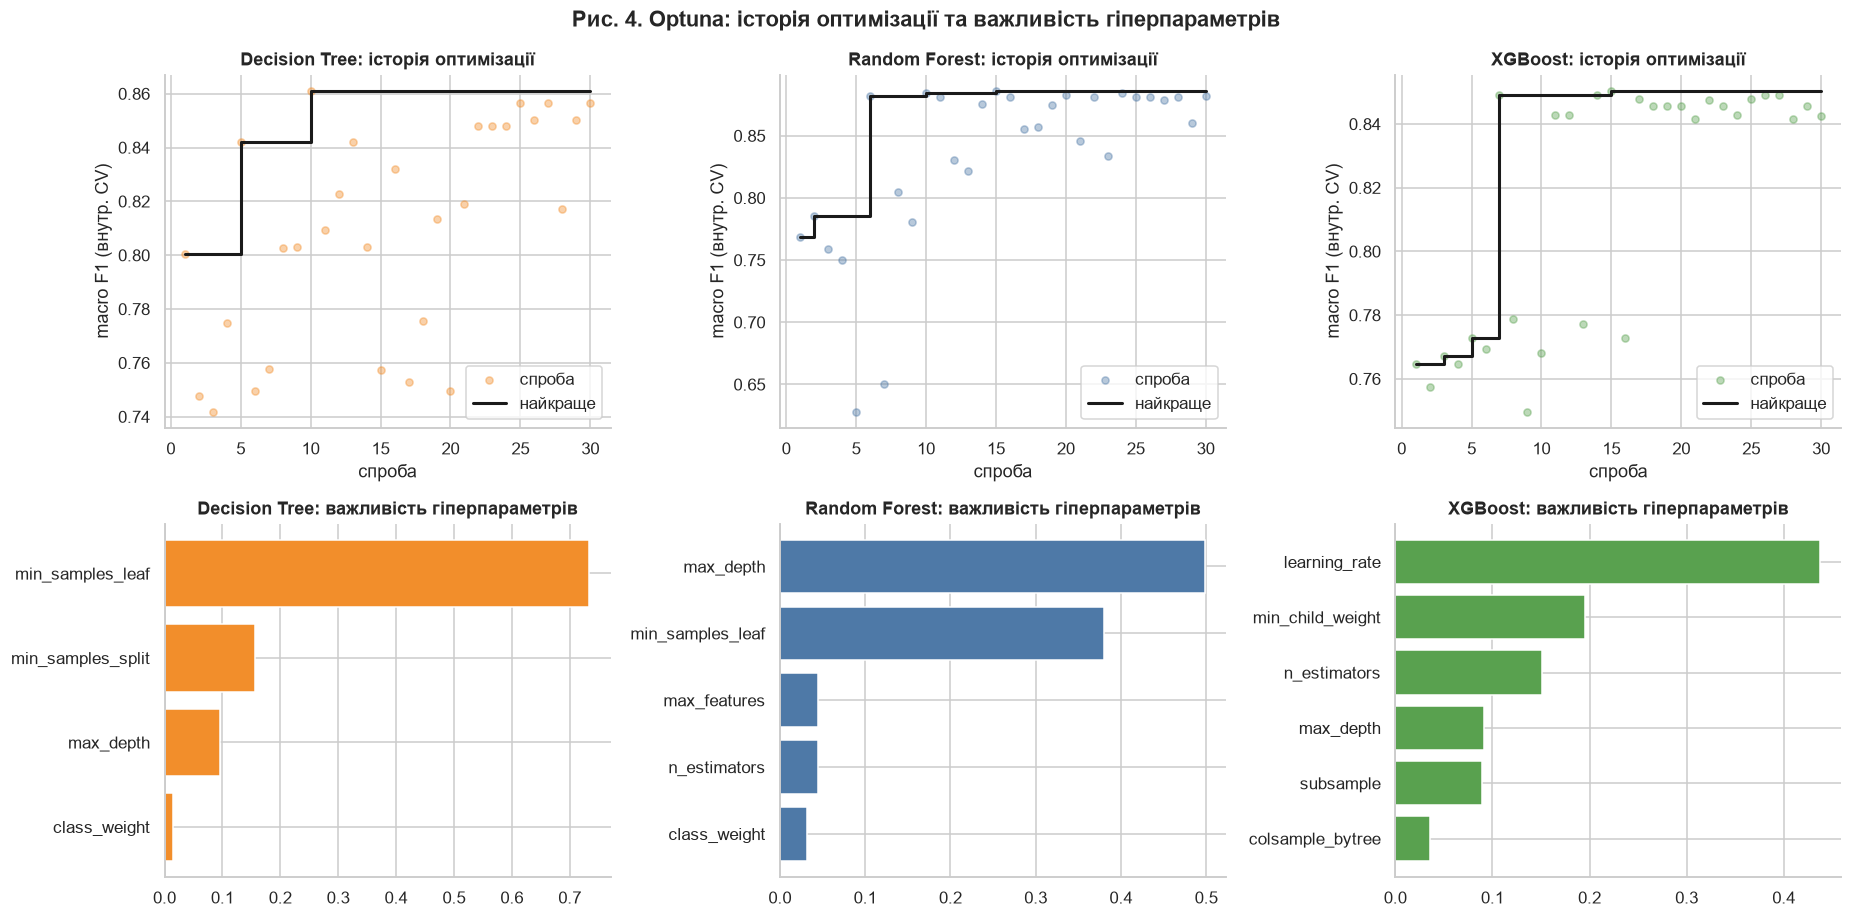

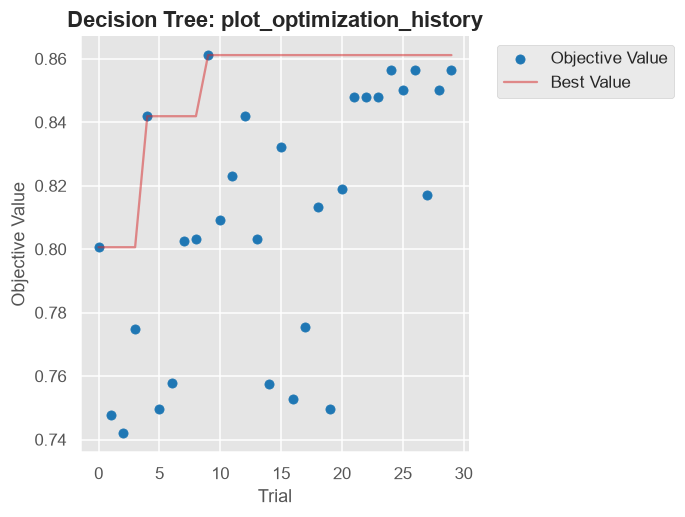

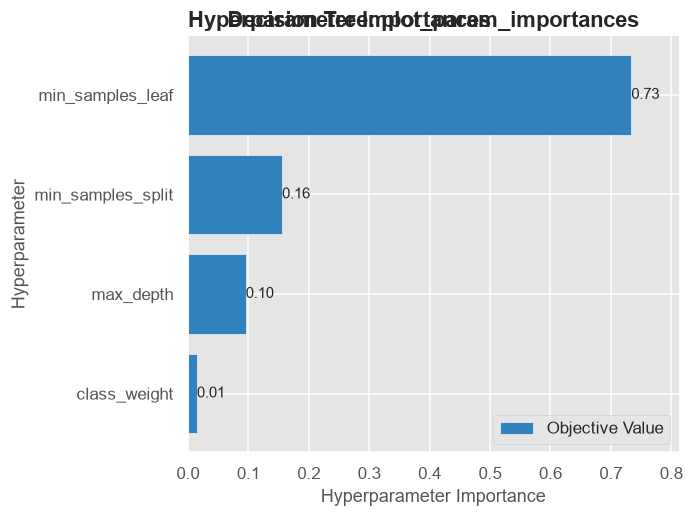

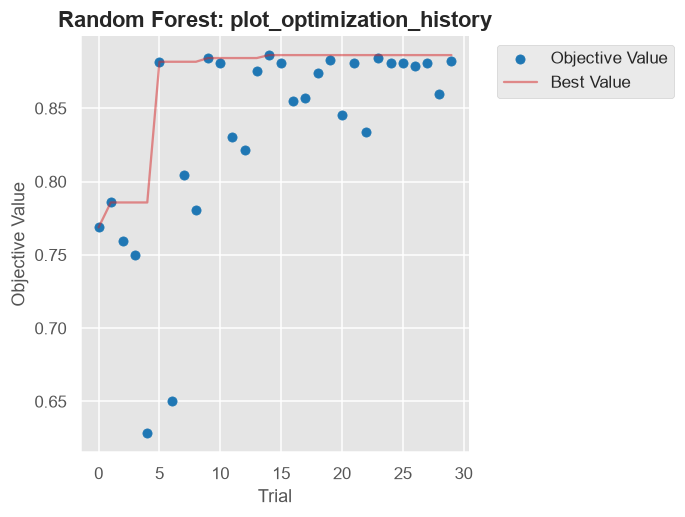

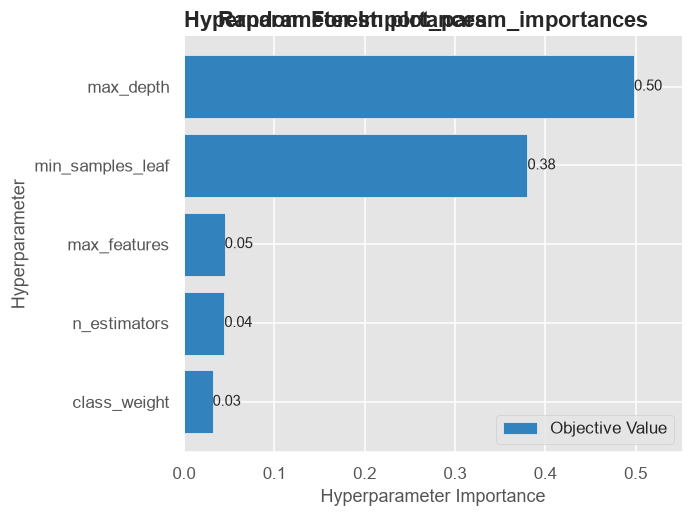

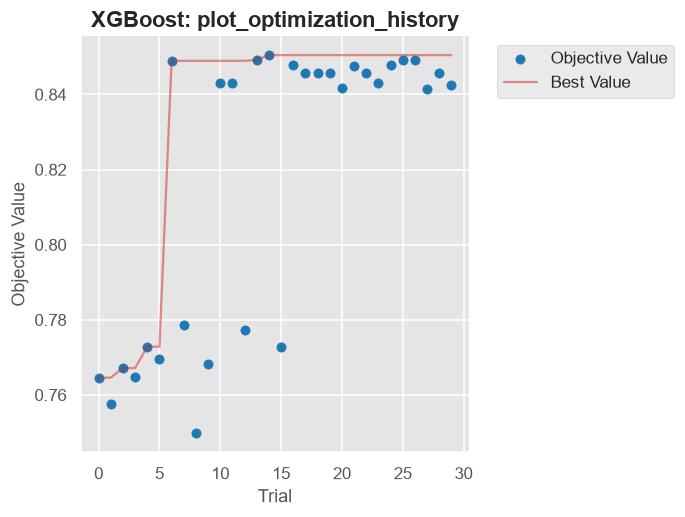

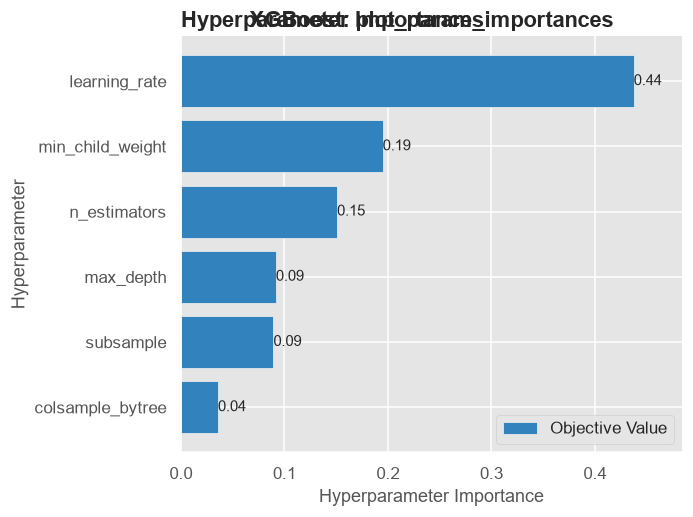

Decision Tree  найкраще знайдено на спробі 10/30; діапазон значень спроб 0.742–0.861; топ-параметр: min_samples_leaf
Random Forest  найкраще знайдено на спробі 15/30; діапазон значень спроб 0.628–0.886; топ-параметр: max_depth
XGBoost        найкраще знайдено на спробі 15/30; діапазон значень спроб 0.750–0.850; топ-параметр: learning_rate


In [ ]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for j, m in enumerate(MODELS):
    vals = np.array([t.value for t in studies[m].trials])
    ax = axes[0, j]
    ax.scatter(range(1, len(vals) + 1), vals, color=COLOR[m], alpha=0.4, s=22, label="спроба")
    ax.step(range(1, len(vals) + 1), np.maximum.accumulate(vals), where="post", color="k", lw=2, label="найкраще")
    ax.set_title(f"{MODEL_NAMES[m]}: історія оптимізації"); ax.set_xlabel("спроба"); ax.set_ylabel("macro F1 (внутр. CV)")
    ax.legend(loc="lower right")
    imp = optuna.importance.get_param_importances(studies[m])
    axes[1, j].barh(list(imp)[::-1], list(imp.values())[::-1], color=COLOR[m])
    axes[1, j].set_title(f"{MODEL_NAMES[m]}: важливість гіперпараметрів")
plt.suptitle("Рис. 4. Optuna: історія оптимізації та важливість гіперпараметрів", fontweight="bold")
plt.tight_layout(); plt.show()

for m in MODELS:
    plot_optimization_history(studies[m]).set_title(f"{MODEL_NAMES[m]}: plot_optimization_history"); plt.tight_layout(); plt.show()
    plot_param_importances(studies[m]).set_title(f"{MODEL_NAMES[m]}: plot_param_importances"); plt.tight_layout(); plt.show()
sns.set_theme(style="whitegrid", context="notebook")
for m in MODELS:
    vals = np.array([t.value for t in studies[m].trials])
    print(f"{MODEL_NAMES[m]:<14} найкраще знайдено на спробі {int(vals.argmax()) + 1}/{len(vals)}; "
          f"діапазон значень спроб {vals.min():.3f}–{vals.max():.3f}; топ-параметр: {next(iter(optuna.importance.get_param_importances(studies[m])))}")

На графіках історії видно, що найкраще значення Optuna знаходить уже на 10-й спробі для дерева і на 15-й для RF та XGBoost. Після цього лінія «найкраще на цей момент» більше не росте. Отже, оптимізація **збіглася**, і 30 спроб вистачає.

Майже всі точки лежать досить близько одна до одної, особливо для дерева (0.74–0.86) і XGBoost (0.75–0.85). Тобто дуже різні параметри дають майже однаковий результат, і це знову ефект стелі. У RF розкид більший (до 0.63): погані спроби мали малу глибину та великі листки, і такий ліс просто «не помічає» маленькі класи.

Найважливіший параметр у дерева — `min_samples_leaf`, у RF — `max_depth`, у XGBoost — `learning_rate`. Мені це здається логічним: усі три параметри визначають, наскільки дрібні деталі модель може вивчити, а для рідкісних класів (8 об'єктів) саме це і вирішальне. Але оскільки результати спроб дуже близькі, ці «важливості» варто сприймати обережно.

## 5. Статистичне порівняння (скоригований t-тест Наде–Бенжіо)
$$t=\frac{\bar d}{\sqrt{\hat\sigma_d^{2}\left(\frac{1}{kr}+\frac{n_{test}}{n_{train}}\right)}},\qquad df=kr-1=14,\quad k=5,\ r=3,\ \frac{n_{test}}{n_{train}}=\frac14$$
Використовуються результати розділу 3 (однакові блоки), α = 0.05.

In [36]:
from scipy import stats

ALPHA, KR, RATIO = 0.05, 15, 1 / 4
f1 = lambda v, m: cv_res[(v, m)]["test_f1m"]

def nadeau_bengio(d):
    d = np.asarray(d, float)
    mean, var = d.mean(), d.var(ddof=1)
    se = np.sqrt((1 / KR + RATIO) * var)
    if se == 0:
        return mean, 0.0, 1.0
    t = mean / se
    return mean, t, 2 * stats.t.sf(abs(t), df=KR - 1)

top2 = sorted(MODELS, key=lambda m: -f1("B", m).mean())[:2]
tests = [(f"{MODEL_NAMES[m]}: B − A", f1("B", m) - f1("A", m)) for m in MODELS]
tests.append((f"Варіант B: {MODEL_NAMES[top2[0]]} − {MODEL_NAMES[top2[1]]}", f1("B", top2[0]) - f1("B", top2[1])))
t5 = pd.DataFrame([dict(zip(["Порівняння", "d̄", "t", "p"], (lbl, *nadeau_bengio(d)))) for lbl, d in tests]).set_index("Порівняння")
t5["Висновок"] = np.where(t5["p"] < ALPHA, "значуща", "незначуща")
print("Таблиця 5. Скоригований t-тест Наде–Бенжіо (macro F1)"); display(t5.round(4))
pair_p = {(a, b): nadeau_bengio(f1("B", a) - f1("B", b))[2] for a, b in itertools.permutations(MODELS, 2)}
print("p-значення для всіх пар у варіанті B:", {f"{a}-{b}": round(p, 3) for (a, b), p in pair_p.items() if a < b})

Таблиця 5. Скоригований t-тест Наде–Бенжіо (macro F1)


,d̄,t,p,Висновок
Порівняння,,,,
Decision Tree: B − A,0.0850,1.9750,0.0683,незначуща
Random Forest: B − A,0.0530,1.8881,0.0799,незначуща
XGBoost: B − A,0.0421,1.3609,0.1951,незначуща
Варіант B: Random Forest − Decision Tree,0.0031,0.2455,0.8097,незначуща


p-значення для всіх пар у варіанті B: {'DT-RF': np.float64(0.81), 'DT-XGB': np.float64(0.38), 'RF-XGB': np.float64(0.345)}


**Аналіз.**
1. **Чи допомагають прапорці пропусків (A vs B)?** Середній приріст у всіх моделей додатний (+0.085, +0.053, +0.042), але за тестом Наде–Бенжіо **жодна різниця не є статистично значущою** (p = 0.068, 0.080, 0.195 > 0.05). Для дерева й лісу p дуже близьке до межі. Я думаю, ефект справжній: прапорці покращили результат на більшості блоків. Довести це статистично заважають дві речі: великий розкид через рідкісні класи і поправка Наде–Бенжіо. Вона чесно враховує, що блоки CV перетинаються, і через це збільшує дисперсію майже вп'ятеро (1/15 + 1/4 замість 1/15).
2. **Чи кращий Random Forest за дерево?** Різниця всього +0.003, p = 0.81, тобто її практично немає. Інші пари (DT–XGB p = 0.38, RF–XGB p = 0.35) теж незначущі. Висновок такий: з типовими параметрами **усі три моделі статистично однакові**, і сказати «RF точно кращий» на цих даних я не можу.

## 6. Фінальна оцінка на тестовій вибірці

In [37]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix

test_pred = {m: final_models[m].predict(X_test) for m in MODELS}
t6 = pd.DataFrame({MODEL_NAMES[m]: {"Accuracy": accuracy_score(y_test, test_pred[m]),
                                    "Macro F1": f1_score(y_test, test_pred[m], average="macro"),
                                    "Balanced acc.": balanced_accuracy_score(y_test, test_pred[m]),
                                    "Помилок": int((test_pred[m] != y_test).sum())} for m in MODELS}).T
print(f"Таблиця 6. Якість фінальних моделей на тесті (n = {len(y_test)})"); display(t6.round(4))

BEST = max(MODELS, key=lambda m: np.mean(nested[m]["tuned"]))      # обираємо за вкладеною CV, а не за тестом
print(f"Найкраща модель (за вкладеною CV): {MODEL_NAMES[BEST]}\n")
print(classification_report(y_test, test_pred[BEST], labels=range(K), target_names=CLASS_NAMES, zero_division=0))

Таблиця 6. Якість фінальних моделей на тесті (n = 180)


,Accuracy,Macro F1,Balanced acc.,Помилок
Decision Tree,0.9944,0.9859,0.975,1.0
Random Forest,1.0000,1.0000,1.000,0.0
XGBoost,1.0000,1.0000,1.000,0.0


Найкраща модель (за вкладеною CV): Random Forest

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00        20
           3       1.00      1.00      1.00       137
           5       1.00      1.00      1.00        13
           U       1.00      1.00      1.00         8

    accuracy                           1.00       180
   macro avg       1.00      1.00      1.00       180
weighted avg       1.00      1.00      1.00       180



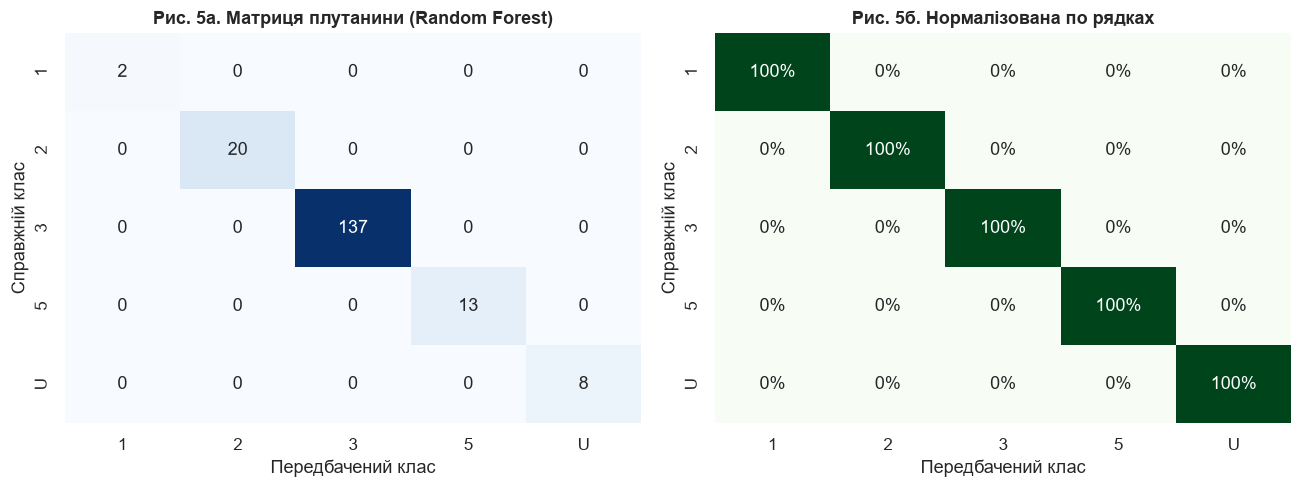

Decision Tree  помилки (справжній → передбачений, к-сть): [('U', '3', 1)]
Random Forest  помилки (справжній → передбачений, к-сть): немає
XGBoost        помилки (справжній → передбачений, к-сть): немає


In [38]:
cm = confusion_matrix(y_test, test_pred[BEST], labels=range(K))
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Greens", vmin=0, vmax=1, cbar=False, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[0].set_title(f"Рис. 5а. Матриця плутанини ({MODEL_NAMES[BEST]})"); axes[1].set_title("Рис. 5б. Нормалізована по рядках")
for ax in axes: ax.set_xlabel("Передбачений клас"); ax.set_ylabel("Справжній клас")
plt.tight_layout(); plt.show()

for m in MODELS:
    c = confusion_matrix(y_test, test_pred[m], labels=range(K))
    errs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(c[i, j])) for i in range(K) for j in range(K) if i != j and c[i, j]]
    print(f"{MODEL_NAMES[m]:<14} помилки (справжній → передбачений, к-сть): {errs or 'немає'}")

На тесті результат майже ідеальний. Random Forest і XGBoost **не помилились жодного разу** (усі метрики 1.000). Дерево помилилось один раз: об'єкт класу `U` воно назвало класом `3`, тому macro F1 у нього 0.986, а balanced accuracy 0.975 (з 8 об'єктів класу `U` знайдено 7). Матриця плутанини найкращої моделі (RF) повністю діагональна, тобто на тесті RF класи не плутає. З OOF-прогнозів у розділі 8 видно, що коли моделі помиляються, то майже завжди «скидають» рідкісний клас (`1`, `2`, `U`) у найбільший клас `3`.

**Чому тест кращий за CV (1.000 проти ~0.97)?** Я вважаю, що тут нам просто пощастило з розбиттям. У тесті лише 2 об'єкти класу `1`, 8 класу `U` і 13 класу `5`, і якщо ці кілька об'єктів «легкі», виходить ідеальний результат. Достатньо однієї помилки на класі `1`, щоб macro F1 впав приблизно на 0.07–0.13. CV усереднює багато розбиттів, тому їй варто довіряти більше, ніж одному тесту на 180 об'єктах.

## 7. Інтерпретація: важливість ознак
1. **MDI** (`feature_importances_`) — на оброблених ознаках (після one-hot, з індикаторами), назви через `get_feature_names_out()`. Для XGBoost це важливість за gain.
2. **Permutation importance** — на тесті, `scoring='f1_macro'`, 10 повторень, для всього пайплайну, тобто на початкових ознаках.

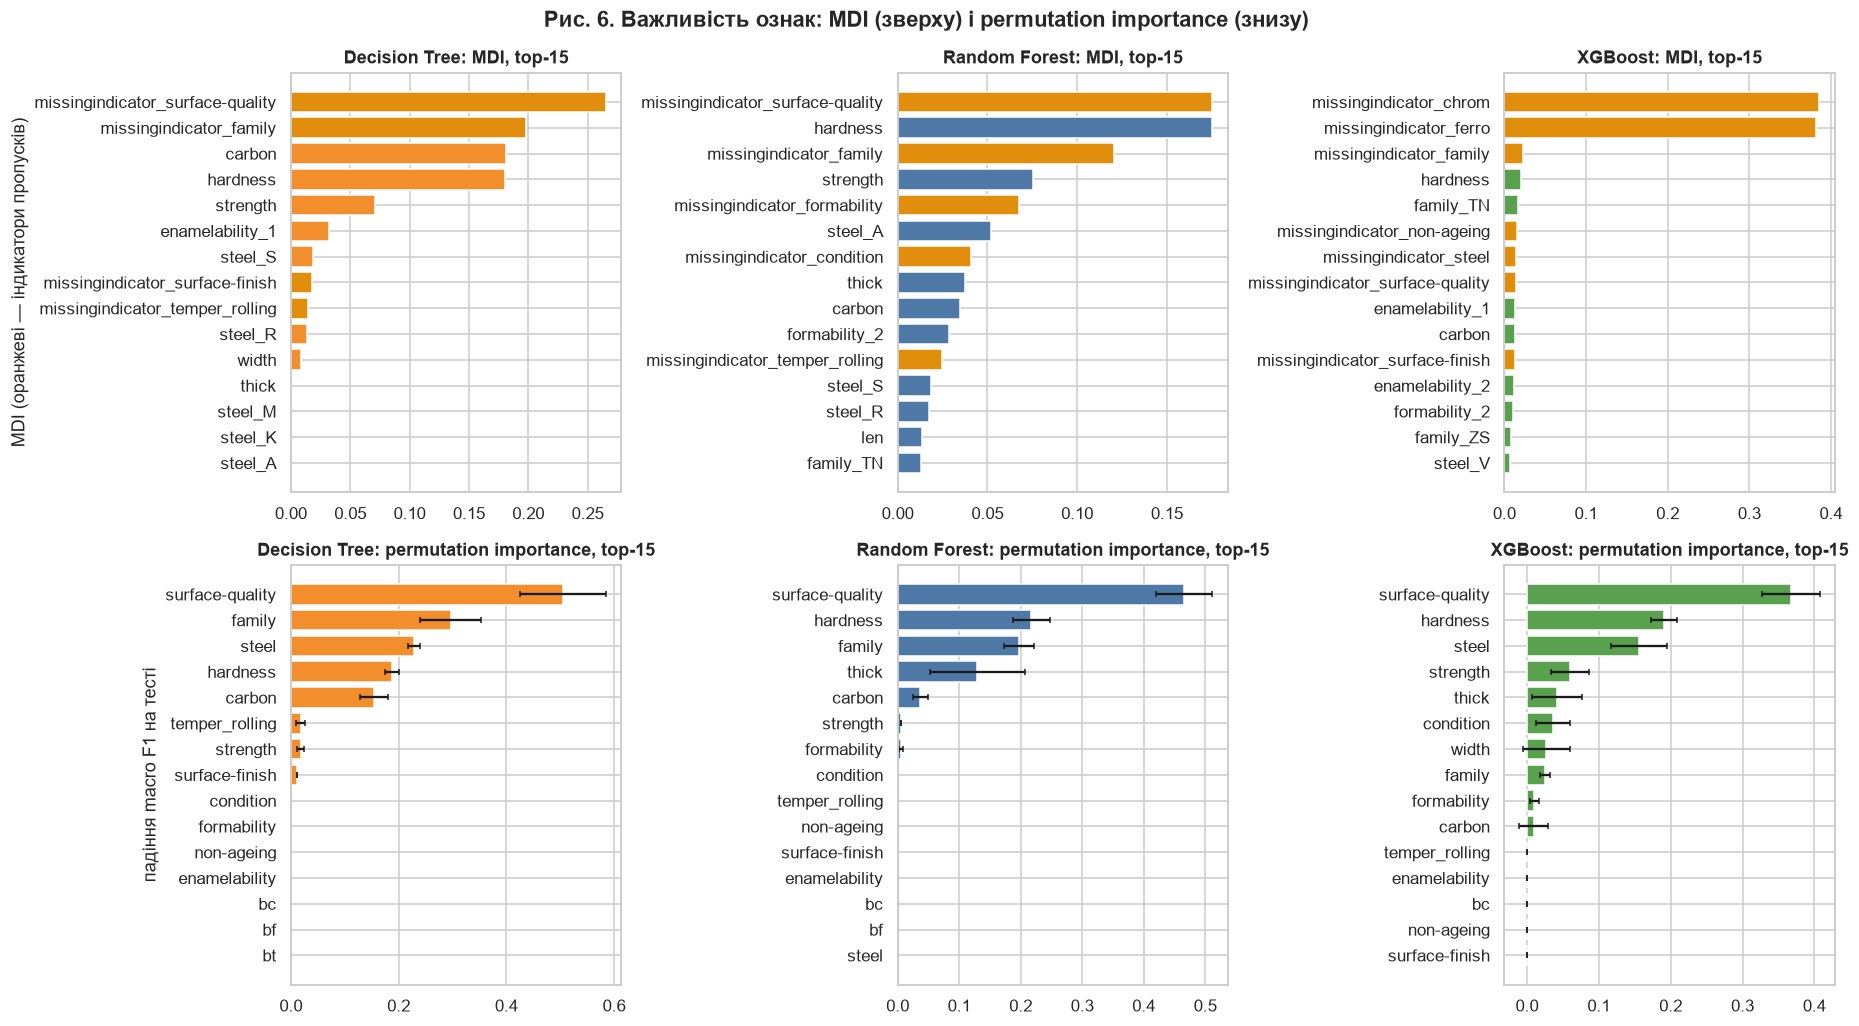

,індикаторів у top-15 MDI,частка MDI індикаторів,top-3 MDI,top-3 permutation,Спірмен MDI vs perm
Decision Tree,4,50%,"missingindicator_surface-quality, missingindic...","surface-quality, family, steel",0.8
Random Forest,5,46%,"missingindicator_surface-quality, hardness, mi...","surface-quality, hardness, family",0.68
XGBoost,7,87%,"missingindicator_chrom, missingindicator_ferro...","surface-quality, hardness, steel",0.43


In [39]:
from sklearn.inspection import permutation_importance

raw_cols = list(X_train.columns)
def raw_name(proc):                       # 'cat__family_TN' -> 'family'; 'miss__missingindicator_bt' -> 'bt'
    n = proc.split("__", 1)[1].replace("missingindicator_", "")
    return next((c for c in sorted(raw_cols, key=len, reverse=True) if n == c or n.startswith(c + "_")), n)

mdi, perm = {}, {}
for m in MODELS:
    pipe = final_models[m]
    names = pipe.named_steps["prep"].get_feature_names_out()
    mdi[m] = pd.Series(pipe.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
    pi = permutation_importance(pipe, X_test, y_test, scoring="f1_macro", n_repeats=10, random_state=SEED)
    perm[m] = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=X_test.columns)

fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
for j, m in enumerate(MODELS):
    top = mdi[m].head(15)[::-1]
    axes[0, j].barh([n.split("__", 1)[1] for n in top.index], top.values,
                    color=[C_IND if "missingindicator" in n else COLOR[m] for n in top.index])
    axes[0, j].set_title(f"{MODEL_NAMES[m]}: MDI, top-15")
    pt = perm[m].sort_values("mean", ascending=False).head(15)[::-1]
    axes[1, j].barh(pt.index, pt["mean"], xerr=pt["std"], color=COLOR[m], capsize=2)
    axes[1, j].set_title(f"{MODEL_NAMES[m]}: permutation importance, top-15")
axes[0, 0].set_ylabel("MDI (оранжеві — індикатори пропусків)"); axes[1, 0].set_ylabel("падіння macro F1 на тесті")
plt.suptitle("Рис. 6. Важливість ознак: MDI (зверху) і permutation importance (знизу)", fontweight="bold")
plt.tight_layout(); plt.show()

summary = {}
for m in MODELS:
    agg = pd.Series(0.0, index=raw_cols)
    for n, v in mdi[m].items(): agg[raw_name(n)] += v
    summary[MODEL_NAMES[m]] = {
        "індикаторів у top-15 MDI": sum("missingindicator" in n for n in mdi[m].head(15).index),
        "частка MDI індикаторів": f"{mdi[m][[('missingindicator' in n) for n in mdi[m].index]].sum():.0%}",
        "top-3 MDI": ", ".join(n.split("__", 1)[1] for n in mdi[m].head(3).index),
        "top-3 permutation": ", ".join(perm[m]["mean"].sort_values(ascending=False).head(3).index),
        "Спірмен MDI vs perm": round(stats.spearmanr(agg.values, perm[m]["mean"].reindex(raw_cols).values).statistic, 2)}
display(pd.DataFrame(summary).T)

**Аналіз.**
* **Чи є прапорці пропусків у top-15 за MDI?** Так, і їх там багато: у дерева 4 прапорці (50 % усієї важливості), у RF 5 (46 %), а в XGBoost 7 (аж 87 % gain). У дерева і в RF **на першому місці** стоїть `missingindicator_surface-quality`, тобто «чи заповнена якість поверхні». Це добре збігається з аналізом у п. 1.4: пропуски пов'язані з класом, і моделі цим активно користуються. Наскільки я розумію, пропуск тут фактично кодує тип продукції (структурні пропуски).
* **Чи узгоджуються MDI і permutation importance?** Частково. Спірмен у дерева 0.80, у RF 0.68, у XGBoost лише 0.43. Спільне в усіх — на перших місцях `surface-quality`, `hardness`, `family`, `steel`. Розбіжності, на мою думку, мають три причини. По-перше, MDI рахується на тренувальних даних і любить ознаки з багатьма різними значеннями (`hardness`, `width`, `thick`), бо по них можна зробити багато розщеплень, навіть якщо реальної користі мало (про це пишуть Strobl та ін., 2007). По-друге, permutation рахується на маленькому тесті, де моделі майже ідеальні, тому перемішування більшості ознак взагалі нічого не змінює і їхня важливість дорівнює нулю. По-третє, ознака та її прапорець несуть схожу інформацію, тож «ділять» важливість між собою.
* **Чому одна ознака має різну важливість у різних моделях?** Одне дерево обирає одну ознаку з кількох схожих і про решту «забуває». RF (з `max_features=0.5`) змушений пробувати різні ознаки, тому розподіляє важливість між ними. XGBoost будує дерева по черзі, кожне виправляє помилки попередніх, тож багато ваги отримують прапорці, які допомагають відрізнити саме рідкісні класи (`missingindicator_chrom`, `missingindicator_ferro`). До того ж у XGBoost важливість рахується через gain, а не через зменшення Джині, тому числа напряму не порівнюються.

## 8. Аналіз розбіжностей між моделями
Об'єкт розбіжності — це об'єкт, на якому прогнози трьох фінальних моделей не всі однакові. Якщо в тесті таких об'єктів менше трьох, таблицю доповнюємо об'єктами з train за **out-of-fold** прогнозами (`cross_val_predict`), позначаючи їх окремо.

In [40]:
from sklearn.model_selection import cross_val_predict

def find_disagreements(index, y_true, preds, source):
    rows = []
    for i, ix in enumerate(index):
        p = [preds[m][i] for m in MODELS]
        if len(set(p)) > 1:
            rows.append({"Об'єкт": f"#{ix}", "Справжній клас": CLASS_NAMES[y_true[i]],
                         **{MODEL_NAMES[m]: CLASS_NAMES[p[k]] for k, m in enumerate(MODELS)}, "Джерело": source, "_ix": ix})
    return pd.DataFrame(rows)

dis = find_disagreements(X_test.index, y_test, test_pred, "test")
print(f"Розбіжностей у тесті: {len(dis)} з {len(y_test)}")
if len(dis) < 3:
    oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof = {m: cross_val_predict(build_pipeline(m, True, studies[m].best_params), X_train, y_train, cv=oof_cv) for m in MODELS}
    oof_dis = find_disagreements(X_train.index, y_train, oof, "train (OOF)")
    print(f"Розбіжностей у train за OOF-прогнозами: {len(oof_dis)} з {len(y_train)}")
    dis = pd.concat([dis, oof_dis.head(3 - len(dis))], ignore_index=True)
print("Таблиця 7. Об'єкти розбіжності"); display(dis.drop(columns="_ix"))

Розбіжностей у тесті: 1 з 180
Розбіжностей у train за OOF-прогнозами: 15 з 718
Таблиця 7. Об'єкти розбіжності


,Об'єкт,Справжній клас,Decision Tree,Random Forest,XGBoost,Джерело
0,#896,U,3,U,U,test
1,#682,2,3,2,2,train (OOF)
2,#406,1,3,1,3,train (OOF)


У тесті моделі не погодились лише **на одному об'єкті з 180** (#896). Через ефект стелі це очікувано. Тому ще два об'єкти я беру з train, але **за out-of-fold прогнозами**, щоб кожен об'єкт передбачала модель, яка його не бачила. У таблиці вони позначені як «train (OOF)». Усього в train за OOF розбіжностей 15 з 718, тобто близько 2 %.

У всіх трьох випадках «неправе» саме одне дерево: воно відносить об'єкт до великого класу `3`. На об'єкті #406 з найрідкіснішого класу `1` помиляється ще й XGBoost, і правильну відповідь дає тільки Random Forest.

### 8.2 Детальний аналіз одного об'єкта розбіжності
**(1) Початкові значення ознак, пропуски і чим їх заповнено**

In [41]:
obj = dis.iloc[0]
pool_X, pool_y = (X_test, y_test) if obj["Джерело"] == "test" else (X_train, y_train)
x_obj = pool_X.loc[[obj["_ix"]]]
true_cls = int(pool_y[pool_X.index.get_loc(obj["_ix"])])
print(f"Об'єкт {obj['Об\'єкт']} ({obj['Джерело']}), справжній клас: {CLASS_NAMES[true_cls]}")

prep0 = final_models["DT"].named_steps["prep"]            # статистики імпутації однакові для всіх моделей (навчались на X_train)
fill = dict(zip(prep0.named_transformers_["num"].feature_names_in_, prep0.named_transformers_["num"].statistics_))
cat_imp = prep0.named_transformers_["cat"].named_steps["impute"]
fill.update(zip(cat_imp.feature_names_in_, cat_imp.statistics_))

missing_raw = [c for c in X.columns if pd.isna(x_obj[c].iloc[0])]
tab = pd.DataFrame({"початкове значення": ["— пропуск" if pd.isna(v) else v for v in x_obj.iloc[0]],
                    "пропущено": ["так" if c in missing_raw else "" for c in X.columns],
                    "заповнено значенням": [fill.get(c, "немає (ознака порожня в train)") if c in missing_raw else "" for c in X.columns]},
                   index=pd.Index(X.columns, name="ознака"))
print(f"Пропущено {len(missing_raw)} з {X.shape[1]} ознак")
display(tab)

Об'єкт #896 (test), справжній клас: U
Пропущено 20 з 31 ознак


,початкове значення,пропущено,заповнено значенням
ознака,,,
family,— пропуск,так,TN
steel,A,,
carbon,0,,
hardness,85,,
temper_rolling,T,,
condition,— пропуск,так,S
formability,— пропуск,так,2
strength,0,,
non-ageing,— пропуск,так,N


**(2) SHAP: топ-5 ознак за модулем внеску в прогнозований клас; (3) ймовірності `predict_proba`**

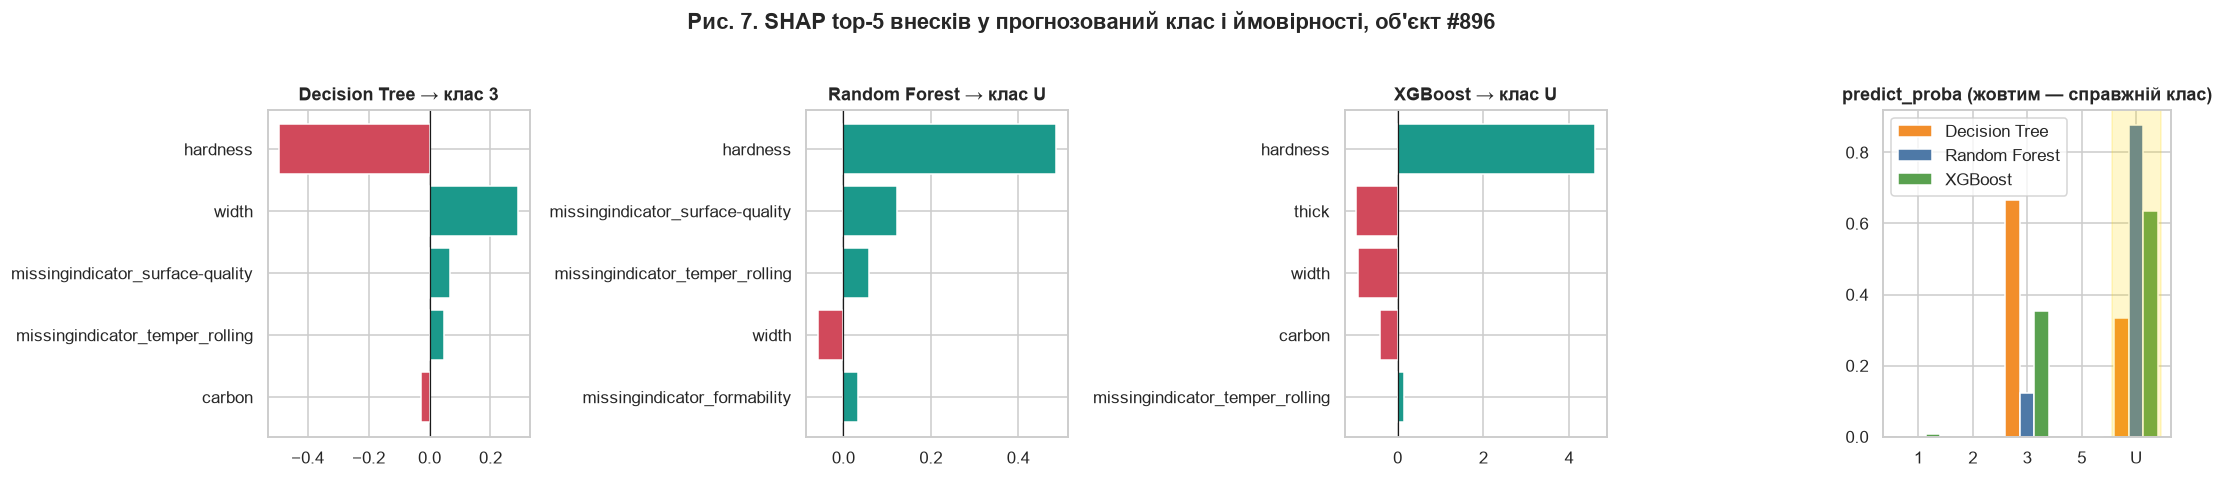

,Decision Tree,Random Forest,XGBoost
1,hardness (-0.492),hardness (+0.487),hardness (+4.599)
2,width (+0.289),missingindicator_surface-quality (+0.123),thick (-0.959)
3,missingindicator_surface-quality (+0.068),missingindicator_temper_rolling (+0.058),width (-0.920)
4,missingindicator_temper_rolling (+0.046),width (-0.058),carbon (-0.403)
5,carbon (-0.029),missingindicator_formability (+0.033),missingindicator_temper_rolling (+0.160)


,Decision Tree,Random Forest,XGBoost
P(клас 1),0.000,0.000,0.008
P(клас 2),0.000,0.000,0.000
P(клас 3),0.667,0.123,0.354
P(клас 5),0.000,0.000,0.002
P(клас U),0.333,0.877,0.636


Перевірка адитивності SHAP (base + Σ внесків vs predict_proba): {'Decision Tree': (0.6667, 0.6667), 'Random Forest': (0.8767, 0.8767), 'XGBoost': (0.6358, 0.6358)}


In [42]:
def softmax(z): e = np.exp(z - z.max()); return e / e.sum()

info = {}
for m in MODELS:
    prep, clf = final_models[m].named_steps["prep"], final_models[m].named_steps["clf"]
    xp, fn = prep.transform(x_obj), prep.get_feature_names_out()
    proba = final_models[m].predict_proba(x_obj)[0]; pred = int(proba.argmax())
    expl = shap.TreeExplainer(clf)
    sv = expl.shap_values(xp)
    sv = (np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv))[0]          # (ознаки, класи)
    total = np.atleast_1d(expl.expected_value) + sv.sum(axis=0)
    s = pd.Series(sv[:, pred], index=[n.split("__", 1)[1] for n in fn])
    info[m] = dict(pred=pred, proba=proba, top=s.reindex(s.abs().sort_values(ascending=False).index).head(5),
                   recon=softmax(total)[pred] if m == "XGB" else total[pred])     # XGBoost пояснює log-odds

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
for ax, m in zip(axes, MODELS):
    s = info[m]["top"][::-1]
    ax.barh(s.index, s.values, color=[C_B if v > 0 else C_BAD for v in s.values]); ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{MODEL_NAMES[m]} → клас {CLASS_NAMES[info[m]['pred']]}")
pd.DataFrame({MODEL_NAMES[m]: info[m]["proba"] for m in MODELS}, index=CLASS_NAMES).plot.bar(
    ax=axes[3], color=[COLOR[m] for m in MODELS], rot=0, width=0.8)
axes[3].axvspan(true_cls - 0.45, true_cls + 0.45, color="gold", alpha=0.2); axes[3].set_title("predict_proba (жовтим — справжній клас)")
plt.suptitle(f"Рис. 7. SHAP top-5 внесків у прогнозований клас і ймовірності, об'єкт {obj['Об\'єкт']}", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

shap_tab = pd.DataFrame({MODEL_NAMES[m]: [f"{n} ({v:+.3f})" for n, v in info[m]["top"].items()] for m in MODELS}, index=range(1, 6))
display(shap_tab)
display(pd.DataFrame({MODEL_NAMES[m]: info[m]["proba"] for m in MODELS}, index=[f"P(клас {c})" for c in CLASS_NAMES]).round(3))
print("Перевірка адитивності SHAP (base + Σ внесків vs predict_proba):",
      {MODEL_NAMES[m]: (round(float(info[m]["recon"]), 4), round(float(info[m]["proba"][info[m]["pred"]]), 4)) for m in MODELS})

**Аналіз об'єкта #896** (справжній клас `U`; дерево каже `3`, RF і XGBoost кажуть `U`).
1. **Пропуски.** У цього виробу пропущено аж 20 з 31 ознаки (`family`, `condition`, `formability`, `chrom`, `phos` …). Усі вони заповнені найчастішим значенням (`TN`, `S`, `2`, …), а найчастіше значення — це, по суті, «типовий виріб класу `3`». Тобто після заповнення об'єкт за багатьма ознаками штучно «схожий» на клас `3`. Відрізнити його допомагають ознаки, які **заповнені**: `surface-quality = G` і `temper_rolling = T`. Їхні прапорці дорівнюють 0 («значення є»), і саме вони є в top-5 SHAP у дерева й RF (а `temper_rolling` — і в XGBoost).
2. **Що каже SHAP.** У всіх трьох моделей головна ознака — `hardness = 85`, але вона працює по-різному. У дерева вона **проти** класу `3` (−0.49), тобто дерево «бачило» аргумент на користь іншого класу, але поріг по `width` (+0.29) усе одно привів його в листок класу `3`. У RF і XGBoost `hardness` — найсильніший аргумент **за** клас `U` (+0.49 у RF і +4.6 у log-odds у XGBoost).
3. **Одне дерево проти ансамблю.** Дерево приймає рішення ланцюжком «так/ні»-порогів і потрапляє в листок, де з 3 навчальних об'єктів 2 мали клас `3`: P(3) = 0.67. RF усереднює 250 дерев і впевнено каже `U` (0.88). XGBoost також обирає `U` (0.64), хоча 0.35 віддає класу `3`. Тобто об'єкт лежить **на межі** між класами `3` і `U`. Ансамблі згладжують помилку окремого порогу, а одне дерево цього зробити не може.
4. Перевірка адитивності проходить: базове значення плюс сума SHAP-внесків точно дорівнює `predict_proba` для всіх трьох моделей.

## Висновки
1. **Найкраща модель.** За CV 5×3 (варіант B) найкращий середній macro F1 у **Random Forest (0.954 ± 0.078)**, але дерево майже таке саме (0.951 ± 0.069): різниця +0.003, p = 0.81, тобто статистично її немає. З XGBoost різниці теж незначущі (p ≈ 0.35–0.38). Після підбору параметрів RF за вкладеною CV найкращий (0.972) і найстабільніший (± 0.039), тоді як у дерева розкид утричі більший (0.915 ± 0.114).
2. **Прапорці пропусків.** Вони покращили macro F1 у всіх моделей (+0.04…+0.085) і підняли accuracy з ~0.95 до ~0.99. Статистично значущим цей приріст не вийшов (p = 0.07–0.20), бо розкид між блоками великий. Але все узгоджується між собою: пропуски не випадкові (4 з 5 ознак пов'язані з класом), а прапорці займають 46–87 % важливості і в дерева та лісу стоять на першому місці.
3. **`best_value` і вкладена CV.** У мене `best_value` (0.85–0.89) виявився на 0.05–0.09 **нижчим** за вкладену CV, хоча мав би бути завищеним. Причина в тому, що внутрішня CV вчиться на меншій частині даних, де рідкісних класів зовсім мало. Звідси я роблю висновок, що `best_value` залежить від умов підбору і як оцінку якості його брати не можна; правильна оцінка тільки з вкладеної CV.
4. **Приріст після оптимізації.** Optuna майже нічого не дала: найбільший приріст у XGBoost (+0.008), у RF −0.006, а дерево навіть погіршилось (−0.059). Типові параметри вже біля стелі, а на малих класах підбір легко «підганяється» під шум, і дерево страждає від цього найбільше.
5. **Найскладніші класи.** Це рідкісні класи `1` (всього 8 об'єктів) і `U` (40). Їх найчастіше плутають із класом `3`: прикладів мало, а багато їхніх ознак пропущено й заповнено значеннями, типовими саме для класу `3`.
6. **Розбіжності.** Моделі майже завжди згодні (1 розбіжність на 180 у тесті, ~2 % у train за OOF). Коли вони розходяться, помиляється зазвичай одне дерево через свої жорсткі пороги, а сам об'єкт лежить на межі класів. Приклад — #896 з P(3) = 0.67 у дерева проти P(U) = 0.88 у RF.
7. **Що обрати на практиці.** Я обираю **Random Forest**. У нього найкраща і найстабільніша якість у вкладеній CV, він майже не залежить від гіперпараметрів, на тесті не має жодної помилки і вчиться швидко (~0.1 с). Дерево варто брати, якщо дуже важливо пояснити кожне рішення: статистично воно не гірше, але набагато менш стабільне. XGBoost тут переваг не дав, а налаштовувати й пояснювати його складніше.

## Відповіді на контрольні питання

**1. Чим випадковий ліс відрізняється від одного дерева з погляду зміщення та дисперсії? Яку роль відіграє декореляція дерев?**
Глибоке дерево дуже добре підлаштовується під навчальні дані, тобто має мале зміщення. Але воно нестабільне: трохи інші дані дають зовсім інше дерево, тобто велику дисперсію. Random Forest навчає багато дерев на різних bootstrap-вибірках і усереднює їх. Зміщення залишається майже таким самим, а дисперсія сильно падає. Це добре видно в моїй роботі: у RF розкид у вкладеній CV ± 0.039, а в дерева ± 0.114. Декореляція (кожне розщеплення бачить лише випадкову частину ознак) потрібна, щоб дерева були різними. Якщо всі дерева однакові, усереднення нічого не дає, а усереднення різних дерев, які помиляються в різних місцях, гасить ці помилки.

**2. Принципова різниця між бустингом і беггінгом. Хто схильніший до перенавчання з ростом кількості дерев?**
У беггінгу (RF) дерева навчаються незалежно й паралельно, а потім голосують, і це зменшує дисперсію. У бустингу (XGBoost) дерева навчаються по черзі, кожне виправляє помилки попередніх, і це зменшує зміщення. У RF додавання дерев майже не шкодить: усереднення просто стабілізується. У бустингу кожне нове дерево ще точніше підганяє модель під train, тож при великій кількості дерев вона може перенавчитися. Тому там використовують `learning_rate`, обмеження глибини та ранню зупинку.

**3. Чому macro F1 і balanced accuracy інформативніші за accuracy при дисбалансі? Різниця між macro та weighted F1.**
Accuracy рахує частку правильних відповідей серед усіх об'єктів, тому її визначає найбільший клас. У моєму датасеті, відповідаючи завжди «3», можна мати 76 % accuracy і не знайти жодного об'єкта інших класів. Macro F1 і balanced accuracy спочатку рахують метрику для кожного класу, а потім просто усереднюють, тож клас з 8 об'єктів важить стільки ж, скільки клас з 684. **Macro**-усереднення — це просте середнє по класах. **Weighted** зважує класи за кількістю об'єктів, тож знову домінує великий клас і результат близький до accuracy.

**4. MCAR, MAR, MNAR. Коли індикатори пропусків найкорисніші? Чи можна за даними відрізнити MAR від MNAR?**
MCAR — пропуск зовсім випадковий і ні від чого не залежить. MAR — пропуск залежить від інших, відомих нам ознак. MNAR — пропуск залежить від самого пропущеного значення або від чогось, що ми не бачимо. Індикатори найкорисніші, коли пропуск **несе інформацію** (MAR, MNAR, структурні пропуски): тоді «значення немає» саме по собі підказує відповідь, як у моїй роботі з `phos` чи `surface-quality`. При MCAR прапорець нічого не додає. MAR від MNAR за даними відрізнити неможливо, бо для перевірки MNAR потрібно знати саме ті значення, яких у нас немає.

**5. Де може виникнути витік даних при імпутації та оптимізації і як його уникнути?**
(1) Якщо заповнити пропуски або зробити one-hot на всьому датасеті до поділу чи до CV, імпутер «бачить» статистики тестових і валідаційних даних. (2) Якщо передати в Optuna вже оброблені дані `X_train_proc`, витік буде всередині внутрішньої CV. (3) Якщо використовувати тестову вибірку для вибору параметрів чи моделі. Як уникнути: вся обробка робиться всередині `Pipeline`, в Optuna передається весь пайплайн, а тест використовується лише один раз наприкінці. У своїй роботі я так і роблю.

**6. Чому `best_value` оптимістично зміщений? Як працює вкладена CV і яку модель вона оцінює?**
`best_value` — це максимум із 30 зашумлених оцінок, отриманих на тих самих даних, на яких ми параметри й обирали. Серед 30 випадкових результатів найкращий майже завжди трохи «пощастивший», тому він завищений. Вкладена CV має два цикли: внутрішній підбирає параметри лише на тренувальній частині зовнішнього блоку, а зовнішній оцінює якість на даних, яких підбір не бачив. Вона оцінює не одну конкретну модель, а **всю процедуру** «підібрати параметри Optuna + навчити модель». (У моїй роботі `best_value` вийшов навіть нижчим, але причина тут в іншому розмірі навчальної вибірки, див. висновок 3.)

**7. Чому звичайний парний t-тест не підходить для CV і яку поправку вносить Наде–Бенжіо?**
Звичайний t-тест вважає 15 оцінок незалежними. Але блоки CV мають спільні тренувальні дані (кожні два тренувальні набори перетинаються приблизно на 75 %), тому оцінки корельовані. Через це тест занижує дисперсію і занадто часто каже «різниця значуща». Наде і Бенжіо додають до множника $\frac{1}{kr}$ доданок $\frac{n_{test}}{n_{train}}$. У мене це 1/15 + 1/4 замість 1/15, тобто дисперсія більша майже вп'ятеро, і висновки стають обережнішими.

**8. Чим MDI відрізняється від permutation importance? Як на них впливають корельовані ознаки?**
MDI рахується «всередині» моделі, на train: наскільки розщеплення по ознаці зменшили неоднорідність. Вона швидка, але зміщена до ознак з багатьма унікальними значеннями й не показує, чи ознака допомагає на нових даних. Permutation importance показує, наскільки падає якість (у мене на тесті), якщо перемішати ознаку. Вона чесніша, але повільніша й залежить від розміру тесту. Корельовані ознаки: у MDI важливість довільно ділиться між ними (модель бере то одну, то іншу). У permutation обидві ознаки можуть отримати занижену важливість, бо коли перемішуємо одну, модель просто використовує іншу.

**9. Що таке SHAP-значення, яку властивість вони задовольняють? Локальне vs глобальне пояснення.**
SHAP-значення — це внесок кожної ознаки в конкретний прогноз, порахований за ідеєю значень Шеплі з теорії ігор (справедливий розподіл «виграшу» між гравцями-ознаками). Головна властивість — **адитивність**: базове значення плюс сума всіх SHAP-внесків точно дорівнює прогнозу моделі. Я перевіряю це в п. 8.2, і для всіх трьох моделей рівність виконується. Локальне пояснення відповідає на питання «чому модель так сказала про **цей** об'єкт». Глобальна важливість відповідає на питання «які ознаки модель використовує загалом», і її отримують, наприклад, усередненням |SHAP| по багатьох об'єктах.

**10. Як XGBoost обробляє пропуски нативно (sparsity-aware split finding)?**
Коли XGBoost шукає розщеплення, він рахує його лише на об'єктах із відомими значеннями. Потім пробує відправити всі об'єкти з пропуском спочатку вліво, потім вправо, і запам'ятовує напрямок, що дає більший приріст. Це «напрямок за замовчуванням», якого модель вчиться з даних, і на новому об'єкті з пропуском вона просто йде туди. Тобто модель сама вирішує, що означає пропуск, без імпутації. Схоже за змістом на наші прапорці пропусків.

**11. Переваги Optuna (TPE, прунінг) порівняно з GridSearchCV і RandomizedSearchCV.**
GridSearch перебирає всі комбінації, і при багатьох параметрах це дуже довго. RandomizedSearch бере комбінації навмання й ніяк не враховує попередні результати. TPE-семплер в Optuna «вчиться» на попередніх спробах і частіше пробує параметри з тих областей, де результат був добрим, тому за ті самі 30 спроб знаходить кращі параметри. Прунінг дозволяє зупинити спробу раніше, якщо вона явно погана. Ще зручно, що простори параметрів можна задавати прямо в коді (умовні, логарифмічні), є готові графіки (історія, важливість параметрів), а з фіксованим `seed` результат відтворюється.